# Global Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd

root_candidates = [
    Path.cwd(), Path.cwd() / "rag_evaluation",
    Path.cwd() / "llm4ehr" / "rag_evaluation", *Path.cwd().parents,
]
BASE_DIR = next((p for p in root_candidates if (p / "manually_reviewed").is_dir()), None)
if BASE_DIR is None:
    raise FileNotFoundError("Open this notebook from the repository or rag_evaluation directory.")

VERSIONS = ["V1", "V2"]
MODELS = ["Llama", "MedLlama"]
MODEL_FILES = {"Llama": "llama_3_2b", "MedLlama": "medllama_2_7b"}
MODEL_TAGS = {"Llama": "llama3.2:3b", "MedLlama": "medllama2:7b"}
OUTPUT_DIR = BASE_DIR / "analysis_outputs" 
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 12})

## Dataset Overview

Publication-style summary of the complete ground-truth dataset. The 38
canonical questions (identified by detailed category) belong to seven broad
question categories, stored as `field_id`: cohort, outcome, time windows,
features, processing, modelling, and evaluation. Broad categories are distinct
from the 38 detailed category identifiers.

Reporting status is counted per paper-question pair, not per unique question.
The figure uses the corrected `ML4EHR.csv`; both reported and not-reported
references are included in the subsequent confusion matrices.

**Suggested caption:** Dataset composition and reference reporting status.
(a) Numbers of papers, canonical questions, and broad question categories.
(b) Reported and not-reported reference counts; percentages use all
paper-question pairs as the denominator.


In [2]:
GOLDEN_DATASET = pd.read_csv(BASE_DIR / "datasets" / "ML4EHR.csv", encoding="utf-8-sig")
dataset_overview = GOLDEN_DATASET.copy()

# The source CSV leaves repeated paper and field metadata blank.
for column in ["article_id", "article_title", "field_id"]:
    dataset_overview[column] = dataset_overview[column].astype("string").str.strip().replace("", pd.NA).ffill()
for column in ["category", "question", "status"]:
    dataset_overview[column] = dataset_overview[column].astype("string").str.strip()
required = ["article_id", "field_id", "category", "question", "status"]
if dataset_overview[required].isna().any().any() or dataset_overview[required].eq("").any().any():
    raise ValueError("Missing paper, field, category, query, or status in the dataset.")
if dataset_overview.duplicated(["article_id", "category"]).any():
    raise ValueError("Duplicate paper/category reference pairs in the dataset.")
dataset_overview["status"] = dataset_overview["status"].str.lower().str.replace(r"[\s_-]+", "_", regex=True)
dataset_overview["status"] = dataset_overview["status"].replace({"not_reported": "no_reported", "non_reported": "no_reported", "unreported": "no_reported"})
if not dataset_overview["status"].isin(["reported", "no_reported"]).all():
    raise ValueError("Unknown reference status in the dataset.")
query_catalog = dataset_overview[["category", "field_id"]].drop_duplicates()
if query_catalog["category"].duplicated().any():
    raise ValueError("A query category is assigned to more than one field.")
dataset_summary = {
    "Papers": dataset_overview["article_id"].nunique(),
    "Queries": len(query_catalog),
    "Detailed categories": dataset_overview["category"].nunique(),
    "Fields": dataset_overview["field_id"].nunique(),
    "Reference pairs": len(dataset_overview),
}
queries_per_field = query_catalog.groupby("field_id", sort=False).size()
reference_status_counts = dataset_overview["status"].value_counts().reindex(["reported", "no_reported"], fill_value=0)
question_wording_count = dataset_overview["question"].nunique()

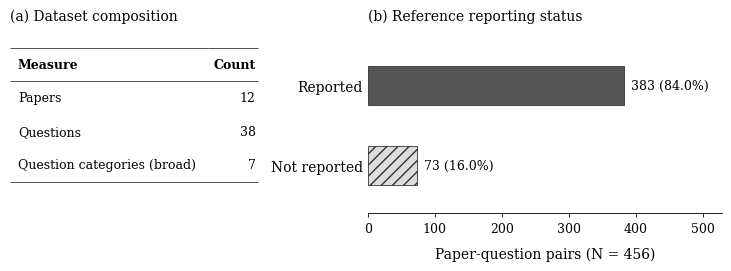

In [3]:
overview_dir = OUTPUT_DIR / "dataset_overview"
overview_dir.mkdir(parents=True, exist_ok=True)
total_references = dataset_summary["Reference pairs"]
overview_totals = pd.Series({
    "Papers": dataset_summary["Papers"],
    "Questions": dataset_summary["Queries"],
    "Question categories (broad)": dataset_summary["Fields"],
    "Reported": int(reference_status_counts["reported"]),
    "Not reported": int(reference_status_counts["no_reported"]),
}, name="Count")
overview_totals.to_csv(overview_dir / "dataset_overview_counts.csv", index_label="Measure")

# Local styling keeps the publication figure independent of other analyses.
with plt.rc_context({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, (summary_ax, status_ax) = plt.subplots(
        1, 2, figsize=(7.2, 2.6), gridspec_kw={"width_ratios": [1, 1.4]},
        layout="constrained",
    )
    summary_ax.set_title("(a) Dataset composition", loc="left", pad=12)
    summary_ax.axis("off")
    table = summary_ax.table(
        cellText=[[label, f"{value:,}"] for label, value in overview_totals.iloc[:3].items()],
        colLabels=["Measure", "Count"],
        colWidths=[0.80, 0.20],
        cellLoc="left",
        colLoc="left",
        bbox=[0, 0.18, 0.98, 0.76],
        edges="open",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    for (row, column), cell in table.get_celld().items():
        cell.PAD = 0.04
        cell.set_edgecolor("#333333")
        cell.set_linewidth(0.6)
        if column == 1:
            cell.get_text().set_ha("right")
        if row == 0:
            cell.visible_edges = "TB"
            cell.get_text().set_weight("bold")
        elif row == 3:
            cell.visible_edges = "B"

    counts = reference_status_counts.to_numpy(dtype=int)
    bars = status_ax.barh(
        ["Reported", "Not reported"], counts, height=0.48,
        color=["#555555", "#dddddd"], edgecolor="#333333", linewidth=0.6,
    )
    bars[1].set_hatch("///")
    status_ax.bar_label(
        bars,
        labels=[f"{count:,} ({count / total_references:.1%})" for count in counts],
        padding=5, fontsize=9,
    )
    status_ax.invert_yaxis()
    status_ax.set_ylim(1.6, -0.6)
    status_ax.set_xlim(0, max(counts) * 1.38)
    status_ax.set_xticks(np.arange(0, max(counts) * 1.38, 100))
    status_ax.set_title("(b) Reference reporting status", loc="left", pad=12)
    status_ax.set_xlabel(f"Paper-question pairs (N = {total_references:,})", labelpad=8)
    status_ax.spines[["top", "right", "left"]].set_visible(False)
    status_ax.spines["bottom"].set_linewidth(0.6)
    status_ax.tick_params(axis="y", length=0)
    status_ax.tick_params(axis="x", width=0.6, length=3)
    status_ax.grid(False)

    for extension in ["png", "svg", "pdf"]:
        fig.savefig(overview_dir / f"dataset_overview.{extension}", dpi=600, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## Analysis 1: Overall reported / not-reported confusion matrices

Combine the separate reported and not-reported result files for Llama and
MedLlama under two RAGAS judge configurations: **V1 = gpt-5.6-luna** and
**V2 = ministral-8b-2512**. V1/V2 identify the evaluation judge, not different
response-model versions. Each comparison uses all **456 paper-query pairs**:
**392 reported** and **64 not reported** references.

Reference statuses are checked against the current `ML4EHR.csv` using paper
and category identifiers. Each comparison must cover the full dataset exactly
once, and all four comparisons must use the same query identifiers.

Rows show reference status; columns show response status. Reported is the
positive class: **TP** = reported/reported, **FN** = reported/not reported,
**FP** = not reported/reported, **TN** = not reported/not reported.
Cells contain counts and percentages within each reference row. These measure
reporting-status detection, independently of RAGAS answer-quality scores and
manual diagnosis labels.

The judge names in this plot identify the evaluation configuration only.
Reporting-status counts are derived from saved response statuses, not from
RAGAS judge scores. If identical responses are evaluated by different judges,
these matrices should be identical. Differences between the current matrices
must therefore not be interpreted as a judge effect; the saved response
statuses differ between configurations.

**Suggested figure caption:** Reporting-status confusion matrices for Llama
3.2 (3B) and MedLlama 2 (7B) across evaluation configurations V1
(RAGAS judge: gpt-5.6-luna) and V2 (RAGAS judge: ministral-8b-2512).
Each matrix contains 456 paper-question pairs: 392 reported and 64 not
reported. Matrix rows denote reference status and columns denote response
status. Cells show counts and reference-row percentages; grayscale intensity
uses a common 0-100% row-percentage scale. The upper-left, upper-right,
lower-left, and lower-right cells correspond to TP, FN, FP, and TN,
respectively. Judge names identify configurations, not the source of the
status classifications; differences must not be attributed solely to the judge.


In [4]:
PAIR_KEYS = ["query_id", "category", "article_id"]
REFERENCE_KEYS = ["article_id", "category"]
OUTCOMES = ["TP", "FN", "FP", "TN"]

# Filenames differ across exports; keep the exact inputs explicit.
STATUS_FILES = {
    ("V1", "Llama"): {
        "reported": "llama_3_2b_V1_reported.csv",
        "no_reported": "llama_3_2b_V1_not_reported.csv",
    },
    ("V1", "MedLlama"): {
        "reported": "medllama_2_7b_V1_reported.csv",
        "no_reported": "medllama2_7b_V1_not_reported.csv",
    },
    ("V2", "Llama"): {
        "reported": "llama_3_2b_V2_reported.csv",
        "no_reported": "llama3_2_2b_V2_not_reported.csv",
    },
    ("V2", "MedLlama"): {
        "reported": "medllama_2_7b_V2_reported.csv",
        "no_reported": "medllama2_7b_V2_not_reported.csv",
    },
}

def normalize_status(values, source):
    normalized = values.astype("string").str.strip().str.lower().str.replace(r"[\s_-]+", "_", regex=True)
    normalized = normalized.replace({"not_reported": "no_reported", "non_reported": "no_reported", "unreported": "no_reported"})
    if not normalized.isin(["reported", "no_reported"]).all():
        raise ValueError(f"Unknown or missing reporting status in {source}")
    return normalized

# Use stable reference identifiers, not CSV row positions.
shared_reference = dataset_overview[REFERENCE_KEYS + ["status"]].rename(columns={"status": "reference_status"}).copy()
shared_reference["reference_status"] = normalize_status(shared_reference["reference_status"], "ML4EHR.csv")
expected_pairs = pd.MultiIndex.from_frame(shared_reference[REFERENCE_KEYS])
frames = []
for version in VERSIONS:
    for model in MODELS:
        partitions = []
        for subset, filename in STATUS_FILES[(version, model)].items():
            path = BASE_DIR / "manually_reviewed" / f"results_{version}" / filename
            frame = pd.read_csv(path, usecols=PAIR_KEYS + ["source_row", "reference_status", "response_status", "response_model", "judge_model"])
            frame["query_id"] = pd.to_numeric(frame["query_id"], errors="raise").astype(int)
            for column in REFERENCE_KEYS:
                frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)
            if frame[PAIR_KEYS].isna().any().any() or frame.duplicated(REFERENCE_KEYS).any():
                raise ValueError(f"Missing or duplicate observation keys in {path.name}")
            if frame["response_model"].isna().any() or not frame["response_model"].eq(MODEL_TAGS[model]).all():
                raise ValueError(f"Unexpected responding model in {path.name}")
            frame["reference_status"] = normalize_status(frame["reference_status"], path.name)
            frame["response_status"] = normalize_status(frame["response_status"], path.name)
            if not frame["reference_status"].eq(subset).all():
                raise ValueError(f"Reference statuses do not match the {subset} partition in {path.name}")
            frame["source_file"] = path.name
            partitions.append(frame)

        combined = pd.concat(partitions, ignore_index=True)
        if combined.duplicated(REFERENCE_KEYS).any():
            raise ValueError(f"Overlapping reference pairs in {version} / {model}")
        actual_pairs = pd.MultiIndex.from_frame(combined[REFERENCE_KEYS])
        missing = expected_pairs.difference(actual_pairs)
        extra = actual_pairs.difference(expected_pairs)
        if len(missing) or len(extra):
            raise ValueError(f"Incomplete reference coverage for {version} / {model}: {len(missing)} missing, {len(extra)} unexpected pairs")
        combined = combined.rename(columns={"reference_status": "file_reference_status"}).merge(
            shared_reference, on=REFERENCE_KEYS, how="left", validate="one_to_one",
        )
        mismatched = combined["file_reference_status"].ne(combined["reference_status"])
        if mismatched.any():
            raise ValueError(f"Result reference statuses disagree with ML4EHR.csv for {version} / {model}: {int(mismatched.sum())} pairs")
        combined["version"], combined["model"] = version, model
        frames.append(combined)

status_data = pd.concat(frames, ignore_index=True)
status_data["judge_model"] = status_data["judge_model"].astype("string").str.strip().replace("", pd.NA)
if status_data["judge_model"].isna().any() or status_data.groupby("version")["judge_model"].nunique().ne(1).any():
    raise ValueError("Each evaluation configuration must have exactly one nonempty RAGAS judge.")
JUDGE_MODELS = status_data.groupby("version")["judge_model"].first().to_dict()

reference_check = status_data.pivot(index=PAIR_KEYS, columns=["version", "model"], values="reference_status")
if reference_check.isna().any().any() or reference_check.nunique(axis=1).ne(1).any():
    raise ValueError("All four comparisons must use the same observations and reference statuses.")
query_mapping = status_data[["query_id", "category"]].drop_duplicates()
if query_mapping["query_id"].duplicated().any() or query_mapping["category"].duplicated().any():
    raise ValueError("Query identifiers and categories must have a one-to-one mapping.")

reference_reported = status_data["reference_status"].eq("reported")
response_reported = status_data["response_status"].eq("reported")
status_data["status_class"] = np.select(
    [reference_reported & response_reported, reference_reported & ~response_reported,
     ~reference_reported & response_reported, ~reference_reported & ~response_reported],
    OUTCOMES, default="invalid",
)
comparison_index = pd.MultiIndex.from_product([VERSIONS, MODELS], names=["version", "model"])
overall_counts = (
    status_data.groupby(["version", "model", "status_class"]).size()
    .unstack("status_class", fill_value=0).reindex(index=comparison_index, columns=OUTCOMES, fill_value=0)
)
status_summary = overall_counts.copy()
status_summary.insert(0, "RAGAS judge", status_summary.index.get_level_values("version").map(JUDGE_MODELS))
status_summary["Reported references"] = overall_counts["TP"] + overall_counts["FN"]
status_summary["Not reported references"] = overall_counts["FP"] + overall_counts["TN"]
status_summary["Total"] = overall_counts.sum(axis=1)
status_summary


status_class            RAGAS judge   TP   FN  FP  TN  Reported references  \
version model                                                                
V1      Llama          gpt-5.6-luna  281  102  11  62                  383   
        MedLlama       gpt-5.6-luna  331   52  23  50                  383   
V2      Llama     ministral-8b-2512  293   90   9  64                  383   
        MedLlama  ministral-8b-2512  336   47  27  46                  383   

status_class      Not reported references  Total  
version model                                     
V1      Llama                          73    456  
        MedLlama                       73    456  
V2      Llama                          73    456  
        MedLlama                       73    456

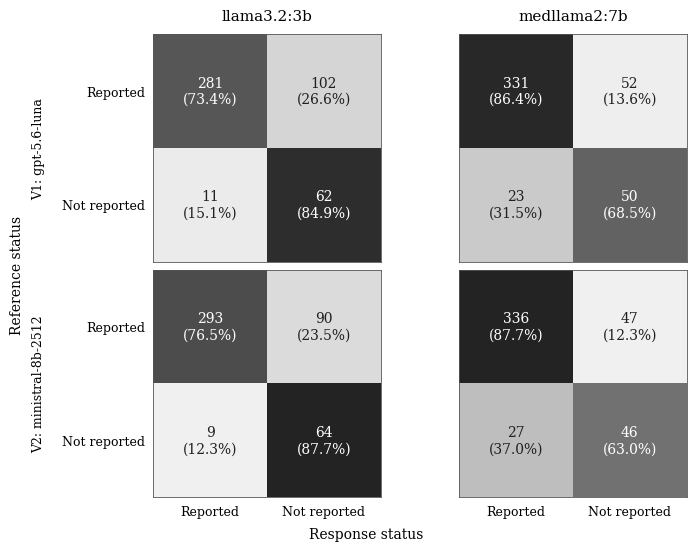

In [5]:
def draw_confusion(ax, record):
    matrix = np.array([[record["TP"], record["FN"]], [record["FP"], record["TN"]]], dtype=int)
    row_totals = matrix.sum(axis=1, keepdims=True)
    proportions = np.divide(
        matrix, row_totals, out=np.full(matrix.shape, np.nan), where=row_totals != 0,
    )
    ax.imshow(proportions, cmap="Greys", vmin=0, vmax=1, interpolation="nearest")
    for row in range(2):
        for column in range(2):
            fraction = proportions[row, column]
            percentage = f"{fraction:.1%}" if np.isfinite(fraction) else "N/A"
            ax.text(
                column, row, f"{matrix[row, column]}\n({percentage})",
                ha="center", va="center", fontsize=10,
                color="white" if fraction > 0.55 else "#202020",
            )
    ax.set_xticks([0, 1], ["Reported", "Not reported"])
    ax.set_yticks([0, 1], ["Reported", "Not reported"])
    ax.tick_params(axis="both", length=0, pad=6)
    for spine in ax.spines.values():
        spine.set_linewidth(0.6)
        spine.set_edgecolor("#555555")
    ax.grid(False)

confusion_dir = OUTPUT_DIR / "reported_vs_nonreported"
confusion_dir.mkdir(parents=True, exist_ok=True)
status_summary.to_csv(confusion_dir / "04_overall_confusion_counts.csv")

with plt.rc_context({
    "font.family": "serif",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
}):
    fig, axes = plt.subplots(
        2, 2, figsize=(7.2, 5.4), sharex=True, sharey=True, layout="constrained",
    )
    for row, version in enumerate(VERSIONS):
        for column, model in enumerate(MODELS):
            ax = axes[row, column]
            draw_confusion(ax, overall_counts.loc[(version, model)])
            if row == 0:
                ax.set_title(MODEL_TAGS[model], pad=10)
            if column == 0:
                ax.set_ylabel(f"{version}: {JUDGE_MODELS[version]}", labelpad=12)
            ax.tick_params(labelbottom=row == len(VERSIONS) - 1, labelleft=column == 0)

    fig.supxlabel("Response status", fontsize=10)
    fig.supylabel("Reference status", fontsize=10)
    for extension in ["png", "svg", "pdf"]:
        fig.savefig(
            confusion_dir / f"04_overall_confusion_matrices.{extension}",
            dpi=600, bbox_inches="tight",
        )
    plt.show()
    plt.close(fig)


## Analysis 2: Only for the cases with `reference_status == reported`

## 2.1 RAGAs Score Analysis

This analysis uses the **reported-reference files only** from
`manually_reviewed/results_V1` and `manually_reviewed/results_V2`.
All 392 reported paper-question pairs are retained for each response model,
including not-reported responses and manually flagged cases. Manual labels
do not alter these RAGAS scores. The 64 not-reported reference pairs are
outside the scope of Analysis 2.

The five original score columns are analyzed separately, without a composite
score or correctness threshold. "Context precision" abbreviates
`llm_context_precision_with_reference` in plots. Means weight each
paper-question pair equally. Missing scores are excluded per metric, never
replaced by zero; valid and missing counts are exported with the summary.

The two panels retain separate judge configurations. Because the saved
responses are not identical across V1/V2, differences between configurations
cannot isolate the effect of the judge. RAGAS scores are automated evaluation
outputs, not human diagnostic labels or observed system accuracy.


In [6]:
from IPython.display import Markdown, display

RAGAS_METRICS = {
    "faithfulness": "Faithfulness",
    "answer_relevancy": "Answer relevancy",
    "context_recall": "Context recall",
    "llm_context_precision_with_reference": "Context precision",
    "answer_correctness": "Answer correctness",
}
RAGAS_MODEL_LABELS = {"Llama": "Llama 3.2 (3B)", "MedLlama": "MedLlama 2 (7B)"}
RAGAS_DIR = OUTPUT_DIR / "ragas_scores_reported"
RAGAS_DIR.mkdir(parents=True, exist_ok=True)

def load_reported_ragas():
    frames = []
    for version in VERSIONS:
        for model in MODELS:
            path = BASE_DIR / "manually_reviewed" / f"results_{version}" / STATUS_FILES[(version, model)]["reported"]
            columns = PAIR_KEYS + ["reference_status", "response_model", "judge_model"] + list(RAGAS_METRICS)
            frame = pd.read_csv(path, usecols=columns)
            query_ids = pd.to_numeric(frame["query_id"], errors="raise")
            if query_ids.isna().any() or query_ids.mod(1).ne(0).any():
                raise ValueError(f"Invalid query identifiers in {path.name}")
            frame["query_id"] = query_ids.astype(int)
            for column in ["article_id", "category", "response_model", "judge_model"]:
                frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)
            if frame[PAIR_KEYS].isna().any().any() or frame.duplicated(REFERENCE_KEYS).any():
                raise ValueError(f"Missing or duplicate reference keys in {path.name}")
            for column, expected in [("response_model", MODEL_TAGS[model]), ("judge_model", JUDGE_MODELS[version])]:
                if frame[column].isna().any() or not frame[column].eq(expected).all():
                    raise ValueError(f"Unexpected {column} in {path.name}")
            frame["reference_status"] = normalize_status(frame["reference_status"], path.name)
            if not frame["reference_status"].eq("reported").all():
                raise ValueError(f"Non-reported references in {path.name}")

            expected = status_data.loc[
                status_data["version"].eq(version) & status_data["model"].eq(model)
                & status_data["reference_status"].eq("reported"), PAIR_KEYS,
            ]
            expected_pairs = pd.MultiIndex.from_frame(expected)
            actual_pairs = pd.MultiIndex.from_frame(frame[PAIR_KEYS])
            if len(expected_pairs.difference(actual_pairs)) or len(actual_pairs.difference(expected_pairs)):
                raise ValueError(f"Reported reference coverage differs from Analysis 1 in {path.name}")
            for metric in RAGAS_METRICS:
                frame[metric] = pd.to_numeric(frame[metric], errors="raise").astype(float)
                present = frame[metric].dropna()
                if not np.isfinite(present).all() or not present.between(0, 1).all():
                    raise ValueError(f"Scores outside [0, 1] in {path.name}: {metric}")
                if present.empty:
                    raise ValueError(f"No valid scores in {path.name}: {metric}")
            frame["version"], frame["model"], frame["source_file"] = version, model, path.name
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)

ragas_data = load_reported_ragas()
ragas_long = ragas_data.melt(
    id_vars=PAIR_KEYS + ["version", "model", "judge_model", "reference_status", "source_file"],
    value_vars=list(RAGAS_METRICS), var_name="metric", value_name="score",
)
paper_ids = sorted(ragas_data["article_id"].unique())
rng = np.random.default_rng(2026)
# Resample whole papers so questions from one paper stay together.
bootstrap_papers = rng.integers(0, len(paper_ids), size=(5000, len(paper_ids)))

def summarize_ragas_metric(group):
    valid = group["score"].dropna()
    paper_stats = (
        group.groupby("article_id")["score"].agg(["sum", "count"])
        .reindex(paper_ids, fill_value=0)
    )
    sampled_sums = paper_stats["sum"].to_numpy()[bootstrap_papers].sum(axis=1)
    sampled_counts = paper_stats["count"].to_numpy()[bootstrap_papers].sum(axis=1)
    bootstrap_means = np.divide(
        sampled_sums, sampled_counts,
        out=np.full(sampled_sums.shape, np.nan), where=sampled_counts > 0,
    )
    low, high = (
        np.nanquantile(bootstrap_means, [0.025, 0.975])
        if paper_stats["count"].gt(0).sum() >= 2 else [np.nan, np.nan]
    )
    return {
        "n_total": len(group), "n_valid": len(valid), "n_missing": group["score"].isna().sum(),
        "n_papers": paper_stats["count"].gt(0).sum(),
        "mean": valid.mean(), "std": valid.std(), "median": valid.median(),
        "q25": valid.quantile(0.25), "q75": valid.quantile(0.75),
        "zero_fraction": valid.eq(0).mean(), "one_fraction": valid.eq(1).mean(),
        "ci_low": low, "ci_high": high,
    }

summary_rows = []
for (version, model, metric), group in ragas_long.groupby(["version", "model", "metric"], sort=False):
    summary_rows.append({
        "version": version, "judge_model": JUDGE_MODELS[version],
        "model": model, "metric": metric, **summarize_ragas_metric(group),
    })
ragas_summary = pd.DataFrame(summary_rows)
ragas_summary.to_csv(RAGAS_DIR / "ragas_summary_reported.csv", index=False)
ragas_long.to_csv(RAGAS_DIR / "ragas_scores_reported_long.csv", index=False)
ragas_mean_table = (
    ragas_summary.pivot(index="metric", columns=["version", "model"], values="mean")
    .reindex(index=list(RAGAS_METRICS), columns=pd.MultiIndex.from_product([VERSIONS, MODELS]))
    .rename(index=RAGAS_METRICS)
)
display(ragas_mean_table.round(3))
missing_scores = int(ragas_summary["n_missing"].sum())
display(Markdown(
    f"**Coverage:** {len(ragas_data):,} model/configuration observations; "
    f"{len(paper_ids)} papers; {ragas_data['query_id'].nunique()} questions; "
    f"{missing_scores} missing metric scores. "
    "Exact per-metric sample sizes and distribution statistics are in the exported summary."
))


V1              V2         
                    Llama MedLlama  Llama MedLlama
metric                                            
Faithfulness        0.715    0.607  0.746    0.677
Answer relevancy    0.456    0.614  0.408    0.527
Context recall      0.396    0.401  0.633    0.623
Context precision   0.762    0.773  0.815    0.817
Answer correctness  0.431    0.424  0.469    0.495

**Coverage:** 1,532 model/configuration observations; 12 papers; 37 questions; 0 missing metric scores. Exact per-metric sample sizes and distribution statistics are in the exported summary.

#### Mean scores

**Figure caption:** Mean RAGAS scores for reported-reference pairs, with
Llama and MedLlama compared within each judge configuration. Points are
pair-weighted means; intervals are exploratory 95% percentile bootstrap
intervals from 5,000 whole-paper resamples (12 papers, fixed random seed).
Questions within a paper remain together during resampling. Scores share a
0-1 scale; larger values indicate higher scores for that metric. Intervals
describe variability across sampled papers, not judge uncertainty or repeated
generation variability. Their overlap is not a model-difference test.


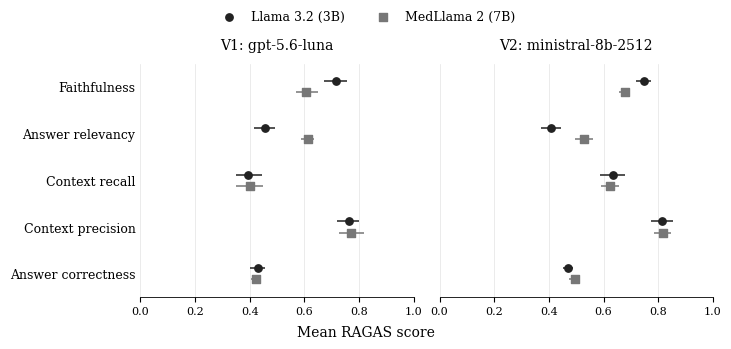

In [7]:
RAGAS_PLOT_STYLE = {
    "font.family": "serif", "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 9,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    "figure.facecolor": "white", "axes.facecolor": "white",
}
RAGAS_MODEL_STYLES = {
    "Llama": {"color": "#222222", "marker": "o", "offset": -0.12},
    "MedLlama": {"color": "#777777", "marker": "s", "offset": 0.12},
}

with plt.rc_context(RAGAS_PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4), sharex=True, sharey=True, layout="constrained")
    for ax, version in zip(axes, VERSIONS):
        for model in MODELS:
            records = (
                ragas_summary.loc[ragas_summary["version"].eq(version) & ragas_summary["model"].eq(model)]
                .set_index("metric").reindex(RAGAS_METRICS)
            )
            style = RAGAS_MODEL_STYLES[model]
            positions = np.arange(len(RAGAS_METRICS)) + style["offset"]
            ax.hlines(positions, records["ci_low"], records["ci_high"], color=style["color"], linewidth=1.1)
            ax.scatter(
                records["mean"], positions, color=style["color"], marker=style["marker"],
                s=28, label=RAGAS_MODEL_LABELS[model], zorder=3,
            )
        ax.set_title(f"{version}: {JUDGE_MODELS[version]}", pad=10)
        ax.set_xlim(0, 1)
        ax.set_xticks(np.linspace(0, 1, 6))
        ax.set_yticks(np.arange(len(RAGAS_METRICS)), list(RAGAS_METRICS.values()))
        ax.set_ylim(len(RAGAS_METRICS) - 0.5, -0.5)
        ax.grid(axis="x", color="#e3e3e3", linewidth=0.5)
        ax.set_axisbelow(True)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.spines["bottom"].set_linewidth(0.6)
        ax.tick_params(axis="y", length=0)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=2, frameon=False, fontsize=9)
    fig.supxlabel("Mean RAGAS score", fontsize=10)
    for extension in ["png", "svg", "pdf"]:
        fig.savefig(RAGAS_DIR / f"01_ragas_mean_scores.{extension}", dpi=600, bbox_inches="tight")
    plt.show()
    plt.close(fig)


#### Score distributions

**Figure caption:** Distributions of individual reported-reference RAGAS
scores. Rows identify judge configurations; columns identify metrics. Each
panel compares Llama (L) and MedLlama (M). Boxes span the interquartile range,
horizontal lines indicate medians, whiskers extend to the most extreme
observations within 1.5 interquartile ranges, and hollow circles show outliers.
All panels share the same 0-1 score scale. Zero and one are retained as valid
scores; a zero is not automatically a human-confirmed retrieval or generation
failure.


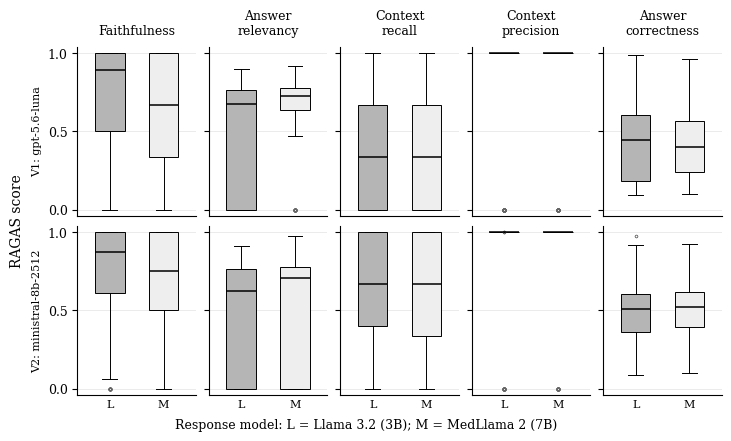

In [8]:
distribution_titles = [
    "Faithfulness", "Answer\nrelevancy", "Context\nrecall",
    "Context\nprecision", "Answer\ncorrectness",
]
with plt.rc_context(RAGAS_PLOT_STYLE):
    fig, axes = plt.subplots(2, 5, figsize=(7.2, 4.3), sharex=True, sharey=True, layout="constrained")
    for row, version in enumerate(VERSIONS):
        for column, (metric, title) in enumerate(zip(RAGAS_METRICS, distribution_titles)):
            ax = axes[row, column]
            values = [
                ragas_data.loc[ragas_data["version"].eq(version) & ragas_data["model"].eq(model), metric].dropna().to_numpy()
                for model in MODELS
            ]
            boxes = ax.boxplot(
                values, positions=[1, 2], widths=0.55, patch_artist=True,
                medianprops={"color": "black", "linewidth": 1.1},
                boxprops={"linewidth": 0.7},
                whiskerprops={"linewidth": 0.7}, capprops={"linewidth": 0.7},
                flierprops={"marker": "o", "markersize": 2, "markerfacecolor": "none",
                            "markeredgecolor": "#666666", "markeredgewidth": 0.4},
            )
            for box, color in zip(boxes["boxes"], ["#b5b5b5", "#eeeeee"]):
                box.set_facecolor(color)
            ax.set_xticks([1, 2], ["L", "M"])
            ax.set_xlim(0.4, 2.6)
            ax.set_ylim(-0.04, 1.04)
            ax.set_yticks([0, 0.5, 1])
            ax.tick_params(axis="x", length=0, labelbottom=row == len(VERSIONS) - 1)
            ax.spines[["top", "right"]].set_visible(False)
            ax.grid(axis="y", color="#e3e3e3", linewidth=0.5)
            ax.set_axisbelow(True)
            if row == 0:
                ax.set_title(title, fontsize=9, pad=9)
            if column == 0:
                ax.set_ylabel(f"{version}: {JUDGE_MODELS[version]}", fontsize=8)
    fig.supylabel("RAGAS score", fontsize=10)
    fig.supxlabel("Response model: L = Llama 3.2 (3B); M = MedLlama 2 (7B)", fontsize=9)
    for extension in ["png", "svg", "pdf"]:
        fig.savefig(RAGAS_DIR / f"02_ragas_score_distributions.{extension}", dpi=600, bbox_inches="tight")
    plt.show()
    plt.close(fig)


In [9]:
mean_scores = ragas_summary.set_index(["version", "model", "metric"])["mean"]
story = ["#### What the RAGAS scores show", ""]
for metric, label in RAGAS_METRICS.items():
    comparisons = []
    for version in VERSIONS:
        llama = mean_scores.loc[(version, "Llama", metric)]
        medllama = mean_scores.loc[(version, "MedLlama", metric)]
        gap = llama - medllama
        comparison = "equal means" if np.isclose(gap, 0) else f"{'Llama' if gap > 0 else 'MedLlama'} higher by {abs(gap):.3f}"
        comparisons.append(f"{version}: {comparison} ({llama:.3f} vs {medllama:.3f}, Llama vs MedLlama)")
    story.append(f"- **{label}:** " + "; ".join(comparisons) + ".")

story += [
    "",
    "**Reading the pattern:** No single metric establishes an overall winner. "
    "Answer correctness is a graded RAGAS score, not the proportion of correct answers. "
    "High faithfulness or context precision does not establish high reference coverage "
    "or answer correctness; the separate scores and distributions should be read together.",
    "",
    "**Limits:** These are descriptive mean differences, not significance tests or human-confirmed "
    "failure diagnoses. V1/V2 use different judges and have differing saved responses, so changes "
    "cannot be interpreted as a controlled judge-only comparison. The bootstrap intervals are "
    "exploratory with only 12 papers and do not account for variability across a new set of questions.",
]
ragas_story = "\n".join(story)
display(Markdown(ragas_story))
_ = (RAGAS_DIR / "ragas_descriptive_summary.md").write_text(ragas_story + "\n", encoding="utf-8")


#### What the RAGAS scores show

- **Faithfulness:** V1: Llama higher by 0.107 (0.715 vs 0.607, Llama vs MedLlama); V2: Llama higher by 0.069 (0.746 vs 0.677, Llama vs MedLlama).
- **Answer relevancy:** V1: MedLlama higher by 0.158 (0.456 vs 0.614, Llama vs MedLlama); V2: MedLlama higher by 0.119 (0.408 vs 0.527, Llama vs MedLlama).
- **Context recall:** V1: MedLlama higher by 0.005 (0.396 vs 0.401, Llama vs MedLlama); V2: Llama higher by 0.010 (0.633 vs 0.623, Llama vs MedLlama).
- **Context precision:** V1: MedLlama higher by 0.010 (0.762 vs 0.773, Llama vs MedLlama); V2: MedLlama higher by 0.003 (0.815 vs 0.817, Llama vs MedLlama).
- **Answer correctness:** V1: Llama higher by 0.007 (0.431 vs 0.424, Llama vs MedLlama); V2: MedLlama higher by 0.025 (0.469 vs 0.495, Llama vs MedLlama).

**Reading the pattern:** No single metric establishes an overall winner. Answer correctness is a graded RAGAS score, not the proportion of correct answers. High faithfulness or context precision does not establish high reference coverage or answer correctness; the separate scores and distributions should be read together.

**Limits:** These are descriptive mean differences, not significance tests or human-confirmed failure diagnoses. V1/V2 use different judges and have differing saved responses, so changes cannot be interpreted as a controlled judge-only comparison. The bootstrap intervals are exploratory with only 12 papers and do not account for variability across a new set of questions.

### 2.1.1 Retrieval Quality by Query Category

This section asks which categories have stronger or weaker **retrieved
evidence**, using the same reported-reference cohort as Section 2.1.
It distinguishes the seven broad fields from the 38 detailed query categories.

- **Context recall:** the judge-assessed fraction of reference statements
  supported by the evaluated context. Lower scores suggest missing coverage.
- **Context precision:** `llm_context_precision_with_reference`, a
  reference-based average-precision score over evaluated context units.
  With one context unit, it reduces to an approximately binary relevance
  verdict; it cannot assess ranking quality among multiple chunks.
- Faithfulness, answer relevancy, answer correctness, and manual diagnosis
  labels are not used to classify retrieval performance here.

Both retrieval metrics use the query, reference, and retrieved contexts,
**not the generated response**. The input audit below checks whether those
three inputs actually differ across runs. Chat-model labels identify the
source runs, not distinct retrievers. Judge scores may differ even with
identical inputs; differences do not by themselves establish a retrieval
change.

All means use valid paper-question scores, with explicit sample sizes and
metric-specific missing counts. No arbitrary pass/fail threshold is imposed.
"Stronger" and "weaker" describe relative scores, not verified retrieval success
or failure. These figures measure evidence quality, not retrieval speed,
cost, document-level recall@k, or performance on not-reported references.


In [10]:
import ast

RETRIEVAL_METRICS = {
    "context_recall": "Context recall",
    "llm_context_precision_with_reference": "Context precision",
}
FIELD_LABELS = {
    "cohort": "Cohort", "outcome": "Outcome", "window": "Time windows",
    "features": "Features", "processing": "Processing",
    "modelling": "Modelling", "evaluation": "Evaluation",
}
RETRIEVAL_DIR = OUTPUT_DIR / "retrieval_by_category"
RETRIEVAL_DIR.mkdir(parents=True, exist_ok=True)
retrieval_data = ragas_data.merge(query_catalog, on="category", how="left", validate="many_to_one")
if retrieval_data["field_id"].isna().any():
    raise ValueError("A retrieval observation has no ground-truth field mapping.")
retrieval_long = retrieval_data.melt(
    id_vars=PAIR_KEYS + ["field_id", "version", "model", "judge_model"],
    value_vars=list(RETRIEVAL_METRICS), var_name="metric", value_name="score",
)

retrieval_summaries = {}
for level in ["field_id", "category"]:
    records = []
    for (version, model, category, metric), group in retrieval_long.groupby(
        ["version", "model", level, "metric"], sort=False,
    ):
        records.append({
            "version": version, "judge_model": JUDGE_MODELS[version], "model": model,
            level: category, "metric": metric,
            "n_queries": group["query_id"].nunique(),
            **summarize_ragas_metric(group),
        })
    summary = pd.DataFrame(records)
    if level == "category":
        summary = summary.merge(query_catalog, on="category", validate="many_to_one")
    summary.to_csv(RETRIEVAL_DIR / f"retrieval_{level}_summary.csv", index=False)
    retrieval_summaries[level] = summary

# Audit the inputs actually used by the two reference-based retrieval metrics.
def parse_evaluated_contexts(value):
    contexts = ast.literal_eval(value)
    if not isinstance(contexts, list) or not all(isinstance(context, str) for context in contexts):
        raise ValueError("Expected a serialized list of evaluated context strings.")
    return tuple(contexts)

audit_frames = []
for version in VERSIONS:
    for model in MODELS:
        path = BASE_DIR / "manually_reviewed" / f"results_{version}" / STATUS_FILES[(version, model)]["reported"]
        frame = pd.read_csv(path, usecols=PAIR_KEYS + [
            "user_input", "reference", "retrieved_contexts", "retrieved_context_count",
            "max_eval_context_chars", "retrieval_scope",
        ])
        frame["query_id"] = pd.to_numeric(frame["query_id"], errors="raise").astype(int)
        for column in REFERENCE_KEYS:
            frame[column] = frame[column].astype("string").str.strip()
        expected = ragas_data.loc[
            ragas_data["version"].eq(version) & ragas_data["model"].eq(model), PAIR_KEYS,
        ]
        frame = expected.merge(frame, on=PAIR_KEYS, how="outer", validate="one_to_one", indicator=True)
        if not frame["_merge"].eq("both").all():
            raise ValueError(f"Evaluation-input audit coverage mismatch in {path.name}")
        if frame[["user_input", "reference", "retrieved_contexts"]].isna().any().any():
            raise ValueError(f"Missing retrieval-evaluation inputs in {path.name}")
        frame["contexts"] = frame["retrieved_contexts"].map(parse_evaluated_contexts)
        frame["context_units"] = frame["contexts"].map(len)
        if not frame["context_units"].eq(frame["retrieved_context_count"]).all():
            raise ValueError(f"Saved context count does not match context contents in {path.name}")
        frame["evaluation_input"] = list(zip(frame["user_input"], frame["reference"], frame["contexts"]))
        frame["version"], frame["model"] = version, model
        audit_frames.append(frame)

retrieval_input_data = pd.concat(audit_frames, ignore_index=True)
retrieval_inputs = retrieval_input_data.pivot(
    index=PAIR_KEYS, columns=["version", "model"], values="evaluation_input",
).reindex(columns=pd.MultiIndex.from_product([VERSIONS, MODELS]))
identical_retrieval_inputs = retrieval_inputs.nunique(axis=1).eq(1)
input_mismatches = retrieval_inputs.index[~identical_retrieval_inputs].to_frame(index=False)
input_mismatches.to_csv(RETRIEVAL_DIR / "retrieval_input_mismatched_pairs.csv", index=False)
audit_records = []
for (version, model), group in retrieval_input_data.groupby(["version", "model"], sort=False):
    audit_records.append({
        "version": version, "model": model, "judge": JUDGE_MODELS[version],
        "pairs": len(group), "min_context_units": group["context_units"].min(),
        "max_context_units": group["context_units"].max(),
        "context_character_caps": ", ".join(group["max_eval_context_chars"].fillna("none").astype(str).unique()),
        "retrieval_scope": ", ".join(group["retrieval_scope"].astype(str).unique()),
    })
retrieval_input_audit = pd.DataFrame(audit_records)
retrieval_input_audit.to_csv(RETRIEVAL_DIR / "retrieval_input_audit.csv", index=False)
display(retrieval_input_audit.set_index(["version", "model"]))
display(Markdown(
    f"**Input comparability:** {int(identical_retrieval_inputs.sum())} of "
    f"{len(identical_retrieval_inputs)} reference pairs have identical query, reference, "
    "and ordered context texts across all four runs. "
    "The character caps above apply to the evaluated evidence, not necessarily the full material retrieved. "
    + ("Every pair has one context unit, so context precision measures its judged relevance, not multi-chunk ranking."
       if retrieval_input_data["context_units"].eq(1).all() else
       "Context-unit counts vary; interpret context precision with the audit table.")
))
if len(input_mismatches):
    display(input_mismatches)


judge  pairs  min_context_units  \
version model                                                   
V1      Llama          gpt-5.6-luna    383                  1   
        MedLlama       gpt-5.6-luna    383                  1   
V2      Llama     ministral-8b-2512    383                  1   
        MedLlama  ministral-8b-2512    383                  1   

                  max_context_units context_character_caps retrieval_scope  
version model                                                               
V1      Llama                     1                   2500      all_papers  
        MedLlama                  1                   2500      all_papers  
V2      Llama                     1                   2500      all_papers  
        MedLlama                  1                   2500      all_papers

**Input comparability:** 383 of 383 reference pairs have identical query, reference, and ordered context texts across all four runs. The character caps above apply to the evaluated evidence, not necessarily the full material retrieved. Every pair has one context unit, so context precision measures its judged relevance, not multi-chunk ranking.

#### Broad-category overview

**Figure caption:** Mean retrieval scores for the seven broad question
categories. Columns are grouped by the explicitly named RAGAS judge:
gpt-5.6-luna (V1) and ministral-8b-2512 (V2). Within each judge group,
columns identify the Llama and MedLlama response-model runs.
The two panels show context recall and reference-based context precision,
with a shared 0-1 grayscale. Row labels show the number of reported
paper-question pairs per run, not the number of unique papers.
Cells show means; the CSV summaries include valid counts, missing counts,
zero-score fractions, and exploratory paper-cluster bootstrap intervals.
Broad-category means weight each available paper-question pair equally,
so categories with more reported references contribute more within a field.


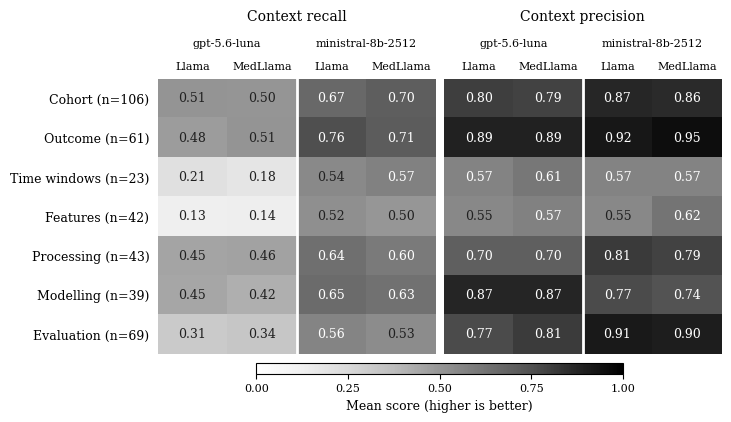

In [11]:
run_columns = pd.MultiIndex.from_product([VERSIONS, MODELS], names=["version", "model"])
run_labels = [f"{version}\n{'L' if model == 'Llama' else 'M'}" for version, model in run_columns]

def draw_retrieval_heatmaps(summary, level, row_order, labels, stem, figsize, label_size, explicit_headers=False):
    with plt.rc_context(RAGAS_PLOT_STYLE):
        fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True, layout="constrained")
        cmap = plt.get_cmap("Greys").copy()
        cmap.set_bad("#dddddd")
        for ax, (metric, title) in zip(axes, RETRIEVAL_METRICS.items()):
            table = (
                summary.loc[summary["metric"].eq(metric)]
                .pivot(index=level, columns=["version", "model"], values="mean")
                .reindex(index=row_order, columns=run_columns)
            )
            values = table.to_numpy(dtype=float)
            heatmap = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=0, vmax=1, aspect="auto")
            for row in range(len(row_order)):
                for column in range(len(run_columns)):
                    score = values[row, column]
                    ax.text(
                        column, row, f"{score:.2f}" if np.isfinite(score) else "N/A",
                        ha="center", va="center", fontsize=label_size,
                        color="white" if score > 0.55 else "#202020",
                    )
            ax.set_title(title, fontsize=10, pad=42 if explicit_headers else 10)
            column_labels = [model for _, model in run_columns] if explicit_headers else run_labels
            ax.set_xticks(np.arange(len(run_columns)), column_labels)
            if explicit_headers:
                judge_axis = ax.secondary_xaxis("top")
                judge_axis.set_xticks([0.5, 2.5], [JUDGE_MODELS[version] for version in VERSIONS])
                judge_axis.tick_params(length=0, labelsize=8, pad=22)
                judge_axis.spines["top"].set_visible(False)
            ax.xaxis.tick_top()
            ax.tick_params(axis="x", length=0, labelsize=8, pad=5)
            ax.set_yticks(np.arange(len(row_order)), labels, fontsize=label_size)
            ax.tick_params(axis="y", length=0, pad=6)
            ax.axvline(1.5, color="white", linewidth=2)
            for spine in ax.spines.values():
                spine.set_visible(False)
        colorbar = fig.colorbar(heatmap, ax=axes, location="bottom", shrink=0.65, aspect=35, pad=0.03)
        colorbar.set_label("Mean score (higher is better)", fontsize=9)
        colorbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
        for extension in ["png", "svg", "pdf"]:
            fig.savefig(RETRIEVAL_DIR / f"{stem}.{extension}", dpi=600, bbox_inches="tight")
        plt.show()
        plt.close(fig)

field_order = query_catalog["field_id"].drop_duplicates().tolist()
field_support = (
    dataset_overview.loc[dataset_overview["status"].eq("reported")]
    .groupby("field_id").size().reindex(field_order)
)
field_labels = [f"{FIELD_LABELS.get(field, field)} (n={field_support[field]})" for field in field_order]
draw_retrieval_heatmaps(
    retrieval_summaries["field_id"], "field_id", field_order, field_labels,
    "01_retrieval_broad_categories", (7.2, 4.1), 9, explicit_headers=True,
)


#### Detailed query categories

**Figure caption:** Retrieval scores for all 38 detailed query categories,
in canonical question order. Columns are grouped by RAGAS judge:
gpt-5.6-luna (V1) and ministral-8b-2512 (V2), with Llama and MedLlama
response-model runs labeled within each group.
Row labels retain the exact category identifiers
and show the number of reported paper references per run. Small sample sizes
require caution: a category represented in only two papers cannot support
the same strength of inference as one represented in twelve. The shortlist
below uses at least five valid papers, while this figure retains every category.
High precision with lower recall means the evaluated evidence may be judged
relevant while still missing reference information; precision alone is not
evidence of complete retrieval.


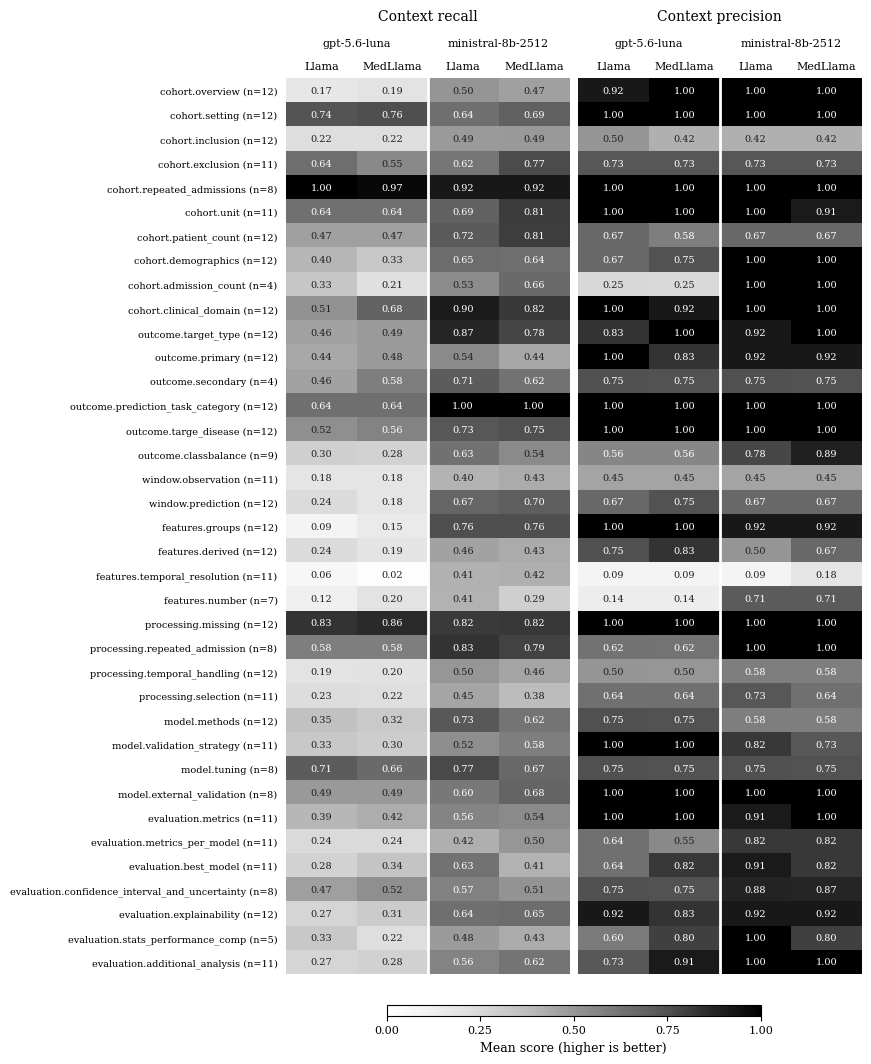

In [12]:
query_order = (
    retrieval_data[["query_id", "category"]].drop_duplicates()
    .sort_values("query_id")["category"].tolist()
)
query_support = (
    dataset_overview.loc[dataset_overview["status"].eq("reported")]
    .groupby("category").size().reindex(query_order)
)
query_labels = [f"{category} (n={query_support[category]})" for category in query_order]
draw_retrieval_heatmaps(
    retrieval_summaries["category"], "category", query_order, query_labels,
    "02_retrieval_detailed_categories", (8.6, 10.5), 7, explicit_headers=True,
)


In [13]:
field_recall = retrieval_summaries["field_id"].query("metric == 'context_recall'")
field_precision = (
    retrieval_summaries["field_id"].query("metric == 'llm_context_precision_with_reference'")
    .set_index(["version", "model", "field_id"])["mean"]
)
retrieval_story = ["#### Where retrieval coverage is stronger or weaker", ""]
for version in VERSIONS:
    for model in MODELS:
        ranked = field_recall.loc[
            field_recall["version"].eq(version) & field_recall["model"].eq(model)
        ].sort_values(["mean", "field_id"], ascending=[False, True]).dropna(subset=["mean"])
        best, weakest = ranked.iloc[0], ranked.iloc[-1]
        retrieval_story.append(
            f"- **{version}, {RAGAS_MODEL_LABELS[model]}:** highest mean recall in "
            f"**{FIELD_LABELS[best.field_id]}** ({best['mean']:.3f}; precision "
            f"{field_precision.loc[(version, model, best.field_id)]:.3f}; n={int(best.n_valid)} pairs); "
            f"lowest in **{FIELD_LABELS[weakest.field_id]}** ({weakest['mean']:.3f}; precision "
            f"{field_precision.loc[(version, model, weakest.field_id)]:.3f}; n={int(weakest.n_valid)} pairs)."
        )

# A minimum-support rule limits the review shortlist, not the plots or summaries.
MIN_REVIEW_PAPERS = 5
query_recall = retrieval_summaries["category"].query("metric == 'context_recall'").copy()
query_precision = (
    retrieval_summaries["category"].query("metric == 'llm_context_precision_with_reference'")
    [["version", "model", "category", "mean", "n_valid"]]
    .rename(columns={"mean": "precision_mean", "n_valid": "precision_n_valid"})
)
query_rankings = query_recall.merge(query_precision, on=["version", "model", "category"], validate="one_to_one")
query_rankings["recall_rank_low_first"] = query_rankings.groupby(["version", "model"])["mean"].rank(method="min")
query_rankings["shortlist_eligible"] = query_rankings["n_papers"].ge(MIN_REVIEW_PAPERS)
query_rankings.to_csv(RETRIEVAL_DIR / "retrieval_query_rankings.csv", index=False)
review_shortlist = (
    query_rankings.loc[query_rankings["shortlist_eligible"] & query_rankings["mean"].notna()]
    .sort_values(["version", "model", "mean", "category"])
    .groupby(["version", "model"], sort=False).head(3)
    [["version", "model", "category", "n_valid", "mean", "precision_mean", "zero_fraction", "ci_low", "ci_high"]]
    .rename(columns={"mean": "recall_mean", "zero_fraction": "zero_recall_fraction"})
)
review_shortlist.to_csv(RETRIEVAL_DIR / "retrieval_low_coverage_shortlist.csv", index=False)
retrieval_story += [
    "",
    "**Detailed review priorities:** The table below lists the three lowest mean-recall "
    f"queries per run among categories with at least {MIN_REVIEW_PAPERS} valid papers. "
    "The zero-recall fraction counts scores equal to zero, not human-confirmed failures. "
    "All categories, including smaller samples, remain in the heatmap and full rankings.",
    "",
    "**Interpretation:** Inspect low-recall categories for missing reference statements in the "
    "evaluated evidence. A high precision score does not rule out incomplete coverage. "
    "The configured context-character cap can omit evidence present in longer retrieved material, "
    "so these scores alone cannot distinguish retrieval omissions from evaluation truncation.",
    "",
    "**Scope:** The rankings are descriptive, not significance tests. They concern only reported "
    "references and the evaluated context representation, not system-wide retrieval efficiency. "
    "Because these metrics do not use generated answers, differing answers do not explain their "
    "score differences when the retrieval-evaluation inputs are identical.",
]
retrieval_story_text = "\n".join(retrieval_story)
display(Markdown(retrieval_story_text))
display(review_shortlist.round(3).set_index(["version", "model", "category"]))
_ = (RETRIEVAL_DIR / "retrieval_category_interpretation.md").write_text(retrieval_story_text + "\n", encoding="utf-8")


#### Where retrieval coverage is stronger or weaker

- **V1, Llama 3.2 (3B):** highest mean recall in **Cohort** (0.505; precision 0.802; n=106 pairs); lowest in **Features** (0.131; precision 0.548; n=42 pairs).
- **V1, MedLlama 2 (7B):** highest mean recall in **Outcome** (0.506; precision 0.885; n=61 pairs); lowest in **Features** (0.136; precision 0.571; n=42 pairs).
- **V2, Llama 3.2 (3B):** highest mean recall in **Outcome** (0.757; precision 0.918; n=61 pairs); lowest in **Features** (0.523; precision 0.548; n=42 pairs).
- **V2, MedLlama 2 (7B):** highest mean recall in **Outcome** (0.708; precision 0.951; n=61 pairs); lowest in **Features** (0.498; precision 0.619; n=42 pairs).

**Detailed review priorities:** The table below lists the three lowest mean-recall queries per run among categories with at least 5 valid papers. The zero-recall fraction counts scores equal to zero, not human-confirmed failures. All categories, including smaller samples, remain in the heatmap and full rankings.

**Interpretation:** Inspect low-recall categories for missing reference statements in the evaluated evidence. A high precision score does not rule out incomplete coverage. The configured context-character cap can omit evidence present in longer retrieved material, so these scores alone cannot distinguish retrieval omissions from evaluation truncation.

**Scope:** The rankings are descriptive, not significance tests. They concern only reported references and the evaluated context representation, not system-wide retrieval efficiency. Because these metrics do not use generated answers, differing answers do not explain their score differences when the retrieval-evaluation inputs are identical.

n_valid  recall_mean  \
version model    category                                             
V1      Llama    features.temporal_resolution       11        0.064   
                 features.groups                    12        0.090   
                 features.number                     7        0.124   
        MedLlama features.temporal_resolution       11        0.018   
                 features.groups                    12        0.153   
                 window.prediction                  12        0.181   
V2      Llama    window.observation                 11        0.403   
                 features.number                     7        0.410   
                 features.temporal_resolution       11        0.411   
        MedLlama features.number                     7        0.290   
                 processing.selection               11        0.377   
                 evaluation.best_model              11        0.409   

                                               precision_mean  \
version model    category                                       
V1      Llama    features.temporal_resolution           0.091   
                 features.groups                        1.000   
                 features.number                        0.143   
        MedLlama features.temporal_resolution           0.091   
                 features.groups                        1.000   
                 window.prediction                      0.750   
V2      Llama    window.observation                     0.455   
                 features.number                        0.714   
                 features.temporal_resolution           0.091   
        MedLlama features.number                        0.714   
                 processing.selection                   0.636   
                 evaluation.best_model                  0.818   

                                               zero_recall_fraction  ci_low  \
version model    category                                                     
V1      Llama    features.temporal_resolution                 0.818   0.000   
                 features.groups                              0.750   0.000   
                 features.number                              0.714   0.000   
        MedLlama features.temporal_resolution                 0.909   0.000   
                 features.groups                              0.750   0.000   
                 window.prediction                            0.667   0.028   
V2      Llama    window.observation                           0.364   0.189   
                 features.number                              0.286   0.167   
                 features.temporal_resolution                 0.364   0.187   
        MedLlama features.number                              0.429   0.071   
                 processing.selection                         0.182   0.222   
                 evaluation.best_model                        0.364   0.174   

                                               ci_high  
version model    category                               
V1      Llama    features.temporal_resolution    0.167  
                 features.groups                 0.194  
                 features.number                 0.333  
        MedLlama features.temporal_resolution    0.060  
                 features.groups                 0.347  
                 window.prediction               0.361  
V2      Llama    window.observation              0.623  
                 features.number                 0.670  
                 features.temporal_resolution    0.643  
        MedLlama features.number                 0.511  
                 processing.selection            0.556  
                 evaluation.best_model           0.659

## 2.2 Manual Diagnosis Analysis

Analyze only `reference_status == reported` from the four reviewed result
files. This is a **human-diagnosis layer**, separate from the RAGAS scores
above. Each row receives one final diagnosis from `manual_label` and the
stored judge classification `failure_category`:

| Final diagnosis | Rule | Meaning |
| --- | --- | --- |
| `retrieval_miss` | `manual_label == retrieval_miss`; overrides `failure_category`, including `ok` | Retrieval failure: context lacks the answer |
| `generation_miss` | `manual_label == generation_miss`; overrides `failure_category`, including `ok` | Generation failure: context contains the answer, but the response is wrong/missed |
| `judge_false_negative` | `manual_label == model_ok` **and** `failure_category` is `wrong` or `missed` | Human-confirmed correct answer that the judge flagged |
| `confirmed_correct` | `manual_label` empty/whitespace **and** `failure_category == ok` | The judge marks the answer correct, and manual review confirms it |
| `unresolved` | Any other combination | Flagged for review and excluded from rates |

For judge comparison, a **correct answer is the positive class**. A judge
false negative is a correct answer the judge flagged (`judge_false_negative`);
a **judge false positive** is a manual retrieval/generation failure the judge
marked `ok`. These terms concern the judge's correctness decision, not
reporting-status TP/FN/FP/TN from Analysis 1.

Rates use resolved rows (all except `unresolved`) as the denominator; the
unresolved count is reported explicitly. A correct answer alone does not prove
that its context contained the answer, so this section does **not** infer human
context recall as one minus the retrieval-failure rate.

In [14]:
MANUAL_DIR = OUTPUT_DIR / "manual_diagnosis_reported"
MANUAL_DIR.mkdir(parents=True, exist_ok=True)
DIAGNOSIS_LABELS = {
    "retrieval_miss": "Retrieval failure",
    "generation_miss": "Generation failure",
    "judge_false_negative": "Judge false negative",
    "confirmed_correct": "Confirmed correct",
    "unresolved": "Unresolved",
}
FAILURE_DIAGNOSES = {"retrieval_miss", "generation_miss"}
CORRECT_DIAGNOSES = {"judge_false_negative", "confirmed_correct"}
JUDGE_FLAGGED = {"wrong", "missed"}

def clean_label(value):
    return "" if pd.isna(value) else str(value).strip().lower()

def diagnose(manual_label, failure_category):
    """Return (diagnosis, review_note) following the rule table above."""
    label, judge = clean_label(manual_label), clean_label(failure_category)
    if label in FAILURE_DIAGNOSES:
        return label, ""
    if label == "model_ok":
        if judge in JUDGE_FLAGGED:
            return "judge_false_negative", ""
        return "unresolved", f"model_ok_with_{judge or 'blank'}_category"
    if not label:
        if judge == "ok":
            return "confirmed_correct", ""
        return "unresolved", f"blank_label_with_{judge or 'blank'}_category"
    return "unresolved", f"unsupported_label_{label}"

def compare_with_judge(diagnosis, failure_category):
    judge = clean_label(failure_category)
    if diagnosis == "unresolved" or judge not in JUDGE_FLAGGED | {"ok"}:
        return "not_comparable"
    human_correct, judge_correct = diagnosis in CORRECT_DIAGNOSES, judge == "ok"
    return {
        (True, True): "agree_correct",
        (False, False): "agree_failure",
        (True, False): "judge_false_negative",
        (False, True): "judge_false_positive",
    }[(human_correct, judge_correct)]

manual_frames = []
for version in VERSIONS:
    for model in MODELS:
        path = BASE_DIR / "manually_reviewed" / f"results_{version}" / STATUS_FILES[(version, model)]["reported"]
        frame = pd.read_csv(path, keep_default_na=False, usecols=PAIR_KEYS + [
            "reference_status", "response_model", "judge_model", "manual_label", "failure_category",
        ])
        frame["csv_row"] = np.arange(2, len(frame) + 2)
        query_ids = pd.to_numeric(frame["query_id"], errors="raise")
        if query_ids.isna().any() or query_ids.mod(1).ne(0).any():
            raise ValueError(f"Invalid query identifiers in {path.name}")
        frame["query_id"] = query_ids.astype(int)
        for column in REFERENCE_KEYS:
            frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)
        if frame[PAIR_KEYS].isna().any().any() or frame.duplicated(REFERENCE_KEYS).any():
            raise ValueError(f"Missing or duplicate review keys in {path.name}")
        if not normalize_status(frame["reference_status"], path.name).eq("reported").all():
            raise ValueError(f"Manual analysis requires reported references only: {path.name}")
        if not frame["response_model"].eq(MODEL_TAGS[model]).all() or not frame["judge_model"].eq(JUDGE_MODELS[version]).all():
            raise ValueError(f"Model or judge mismatch in {path.name}")
        expected = ragas_data.loc[ragas_data["version"].eq(version) & ragas_data["model"].eq(model), PAIR_KEYS]
        frame = frame.merge(expected, on=PAIR_KEYS, how="outer", validate="one_to_one", indicator=True)
        if not frame["_merge"].eq("both").all():
            raise ValueError(f"Manual review coverage differs from Section 2.1 in {path.name}")
        frame = frame.drop(columns="_merge")
        decisions = [diagnose(label, judge) for label, judge in zip(frame["manual_label"], frame["failure_category"])]
        frame["diagnosis"] = [diagnosis for diagnosis, _ in decisions]
        frame["review_note"] = [note for _, note in decisions]
        frame["comparison"] = [
            compare_with_judge(diagnosis, judge) for diagnosis, judge in zip(frame["diagnosis"], frame["failure_category"])
        ]
        frame["version"], frame["model"], frame["source_file"] = version, model, path.name
        manual_frames.append(frame)

manual_data = pd.concat(manual_frames, ignore_index=True).merge(
    query_catalog, on="category", how="left", validate="many_to_one",
)
if manual_data["field_id"].isna().any():
    raise ValueError("Missing broad-category mapping in manual diagnosis data.")

def safe_rate(numerator, denominator):
    return numerator / denominator if denominator else np.nan

def summarize_manual_group(group):
    diagnoses = group["diagnosis"].value_counts()
    comparisons = group["comparison"].value_counts()
    counts = {key: int(diagnoses.get(key, 0)) for key in DIAGNOSIS_LABELS}
    agree_correct, agree_failure, judge_fp = (
        int(comparisons.get(key, 0)) for key in ["agree_correct", "agree_failure", "judge_false_positive"]
    )
    judge_fn = int(comparisons.get("judge_false_negative", 0))
    n_resolved = len(group) - counts["unresolved"]
    n_correct = counts["judge_false_negative"] + counts["confirmed_correct"]
    n_failure = counts["retrieval_miss"] + counts["generation_miss"]
    n_compared = agree_correct + agree_failure + judge_fn + judge_fp
    return {
        "n_total": len(group), "n_resolved": n_resolved, "n_papers": group["article_id"].nunique(),
        **counts, "n_correct": n_correct, "n_failure": n_failure,
        "correct_rate": safe_rate(n_correct, n_resolved),
        "retrieval_failure_rate": safe_rate(counts["retrieval_miss"], n_resolved),
        "generation_failure_rate": safe_rate(counts["generation_miss"], n_resolved),
        "n_compared": n_compared, "agree_correct": agree_correct, "agree_failure": agree_failure,
        "judge_false_positive": judge_fp,
        "judge_accuracy": safe_rate(agree_correct + agree_failure, n_compared),
        # Share of human-correct answers flagged / human failures passed by the judge.
        "judge_false_negative_rate": safe_rate(judge_fn, agree_correct + judge_fn),
        "judge_false_positive_rate": safe_rate(judge_fp, agree_failure + judge_fp),
    }

manual_summary = pd.DataFrame([
    {"version": version, "judge_model": JUDGE_MODELS[version], "model": model, **summarize_manual_group(group)}
    for (version, model), group in manual_data.groupby(["version", "model"], sort=False)
]).set_index(["version", "model"]).reindex(comparison_index)
manual_summary.to_csv(MANUAL_DIR / "manual_diagnosis_summary.csv")
manual_data.to_csv(MANUAL_DIR / "manual_diagnosis_rows.csv", index=False)
manual_disagreements = manual_data.loc[manual_data["comparison"].isin(["judge_false_negative", "judge_false_positive"])]
manual_disagreements.to_csv(MANUAL_DIR / "judge_human_disagreements.csv", index=False)
manual_review_flags = manual_data.loc[manual_data["review_note"].ne("")]
manual_review_flags.to_csv(MANUAL_DIR / "manual_review_flags.csv", index=False)

display(manual_summary[[
    "n_total", "n_resolved", "retrieval_miss", "generation_miss", "judge_false_negative",
    "confirmed_correct", "unresolved", "correct_rate", "judge_false_positive", "judge_accuracy",
]].round(3))
display(Markdown(
    f"**Review coverage:** {int(manual_summary['n_resolved'].sum())} of {len(manual_data)} "
    f"run-specific observations resolved; {int(manual_summary['confirmed_correct'].sum())} are "
    f"`confirmed_correct` (blank label + judge `ok`). {len(manual_review_flags)} rows flagged for review. "
    "Original CSV values are unchanged."
))
if len(manual_review_flags):
    display(manual_review_flags[[
        "version", "model", "query_id", "category", "article_id", "csv_row",
        "manual_label", "failure_category", "review_note",
    ]])

n_total  n_resolved  retrieval_miss  generation_miss  \
version model                                                            
V1      Llama         383         383             121              120   
        MedLlama      383         383             117              151   
V2      Llama         383         383             122              112   
        MedLlama      383         383             119              146   

                  judge_false_negative  confirmed_correct  unresolved  \
version model                                                           
V1      Llama                      111                 31           0   
        MedLlama                    89                 26           0   
V2      Llama                      136                 13           0   
        MedLlama                   104                 14           0   

                  correct_rate  judge_false_positive  judge_accuracy  
version model                                                         
V1      Llama            0.371                     7           0.692  
        MedLlama         0.300                     2           0.762  
V2      Llama            0.389                     7           0.627  
        MedLlama         0.308                     5           0.715

**Review coverage:** 1532 of 1532 run-specific observations resolved; 84 are `confirmed_correct` (blank label + judge `ok`). 0 rows flagged for review. Original CSV values are unchanged.

### Manual diagnosis outcomes

**Figure caption:** Final diagnoses of reported-reference pairs, by judge
configuration and response model. Correct answers are split into
`confirmed_correct` (judge `ok`, confirmed in review) and
`judge_false_negative` (judge flagged, human-confirmed correct). Bars use all
input rows as the denominator, including any unresolved cases; segments of 1-10%
are labelled above the bar. Summary tables report exact counts and resolved-only
rates.

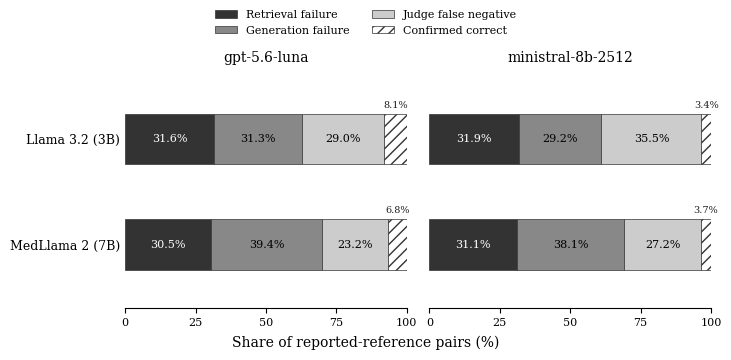

In [15]:
manual_styles = {
    "retrieval_miss": ("#333333", "", "white"),
    "generation_miss": ("#888888", "", "black"),
    "judge_false_negative": ("#cccccc", "", "black"),
    "confirmed_correct": ("white", "///", "black"),
    "unresolved": ("white", "xx", "black"),
}
shown_diagnoses = [key for key in DIAGNOSIS_LABELS if manual_summary[key].sum() > 0]
with plt.rc_context(RAGAS_PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.5), sharex=True, sharey=True, layout="constrained")
    for ax, version in zip(axes, VERSIONS):
        records = manual_summary.loc[version].reindex(MODELS)
        left = np.zeros(len(MODELS))
        for diagnosis in shown_diagnoses:
            percentages = records[diagnosis].to_numpy(dtype=float) / records["n_total"].to_numpy() * 100
            color, hatch, text_color = manual_styles[diagnosis]
            ax.barh(
                np.arange(len(MODELS)), percentages, left=left, height=0.48,
                color=color, hatch=hatch, edgecolor="#333333", linewidth=0.5,
                label=DIAGNOSIS_LABELS[diagnosis],
            )
            for row, percentage in enumerate(percentages):
                if percentage >= 10:
                    ax.text(left[row] + percentage / 2, row, f"{percentage:.1f}%",
                            ha="center", va="center", fontsize=8, color=text_color)
                elif percentage >= 1:
                    # Too narrow for an inside label: annotate just above the segment.
                    ax.text(left[row] + percentage / 2, row - 0.28, f"{percentage:.1f}%",
                            ha="center", va="bottom", fontsize=7, color="#202020")
            left += percentages
        ax.set_title(JUDGE_MODELS[version], fontsize=10, pad=10)
        ax.set_yticks(np.arange(len(MODELS)), [RAGAS_MODEL_LABELS[model] for model in MODELS])
        ax.set_ylim(len(MODELS) - 0.4, -0.6)
        ax.set_xlim(0, 100)
        ax.set_xticks([0, 25, 50, 75, 100])
        ax.tick_params(axis="y", length=0)
        ax.spines[["top", "right", "left"]].set_visible(False)
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="outside upper center", ncol=2, frameon=False, fontsize=8)
    fig.supxlabel("Share of reported-reference pairs (%)", fontsize=10)
    for extension in ["png", "svg", "pdf"]:
        fig.savefig(MANUAL_DIR / f"01_manual_diagnosis_outcomes.{extension}", dpi=600, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### Human-judge agreement

**Figure caption:** Human diagnosis versus the stored judge classification
(`failure_category`). "Flagged" combines `wrong` and `missed`. Cells show counts
and percentages within each human-diagnosis row. With a correct answer as the
positive class, the upper-right cell holds judge false positives (human failure,
judge `ok`) and the lower-left holds judge false negatives (human correct,
judge flagged); the diagonal cells are agreements. Unresolved rows are
excluded, with comparable counts reported in the summary.

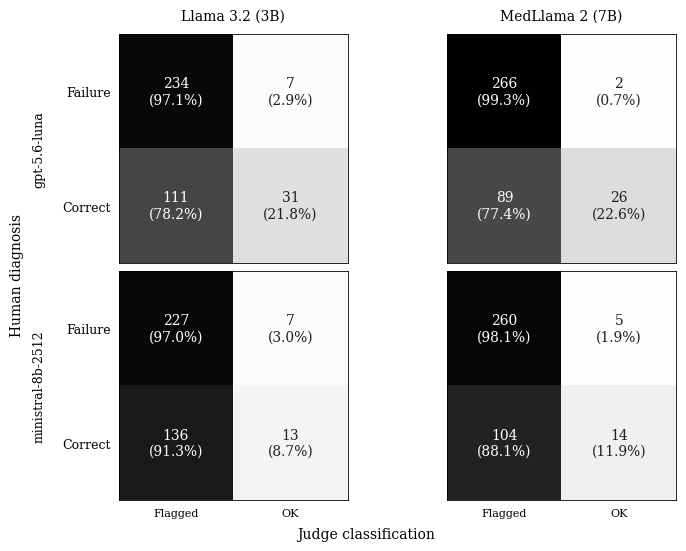

In [16]:
with plt.rc_context(RAGAS_PLOT_STYLE):
    fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.4), sharex=True, sharey=True, layout="constrained")
    for row, version in enumerate(VERSIONS):
        for column, model in enumerate(MODELS):
            ax = axes[row, column]
            record = manual_summary.loc[(version, model)]
            matrix = np.array([
                [record["agree_failure"], record["judge_false_positive"]],
                [record["judge_false_negative"], record["agree_correct"]],
            ], dtype=int)
            totals = matrix.sum(axis=1, keepdims=True)
            fractions = np.divide(matrix, totals, out=np.full(matrix.shape, np.nan), where=totals > 0)
            ax.imshow(fractions, cmap="Greys", vmin=0, vmax=1, interpolation="nearest")
            for y in range(2):
                for x in range(2):
                    fraction = fractions[y, x]
                    percentage = f"{fraction:.1%}" if np.isfinite(fraction) else "N/A"
                    ax.text(x, y, f"{matrix[y, x]}\n({percentage})", ha="center", va="center",
                            fontsize=10, color="white" if fraction > 0.55 else "#202020")
            ax.set_xticks([0, 1], ["Flagged", "OK"])
            ax.set_yticks([0, 1], ["Failure", "Correct"])
            ax.tick_params(length=0, pad=6, labelbottom=row == 1, labelleft=column == 0)
            if row == 0:
                ax.set_title(RAGAS_MODEL_LABELS[model], fontsize=10, pad=10)
            if column == 0:
                ax.set_ylabel(JUDGE_MODELS[version], fontsize=9, labelpad=12)
            for spine in ax.spines.values():
                spine.set_linewidth(0.6)
    fig.supxlabel("Judge classification", fontsize=10)
    fig.supylabel("Human diagnosis", fontsize=10)
    for extension in ["png", "svg", "pdf"]:
        fig.savefig(MANUAL_DIR / f"02_human_judge_agreement.{extension}", dpi=600, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### Manual diagnosis by broad category

**Figure caption:** Retrieval failures, generation failures, and correct answers
(`confirmed_correct` + `judge_false_negative`) across the seven broad query
categories. Rates use resolved rows within each category/run, so the three rates
sum to 100%. Darker cells indicate a larger share of the named outcome: lower is
preferable for failure rates, higher for correctness. These are empirical
diagnosis proportions, **not RAGAS scores**. Detailed-query summaries are
exported alongside the broad-category summaries.

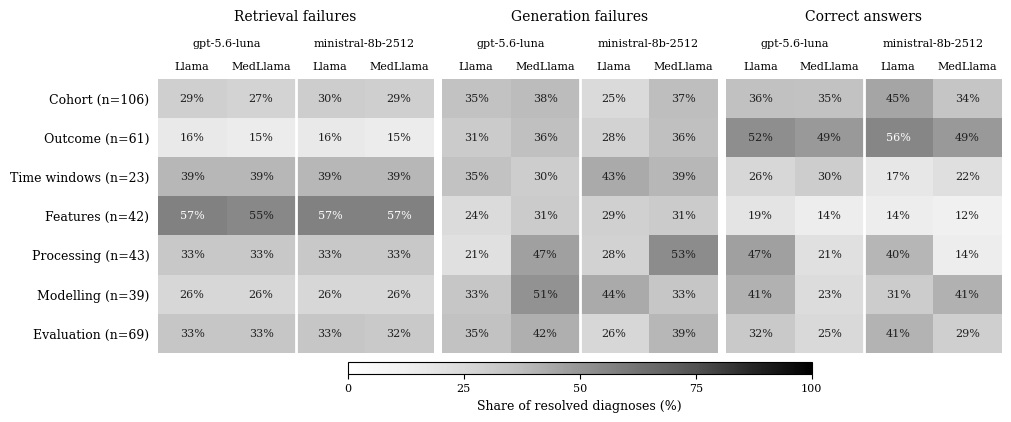

In [17]:
manual_category_summaries = {}
for level in ["field_id", "category"]:
    records = [
        {"version": version, "judge_model": JUDGE_MODELS[version], "model": model,
         level: category, **summarize_manual_group(group)}
        for (version, model, category), group in manual_data.groupby(["version", "model", level], sort=False)
    ]
    summary = pd.DataFrame(records)
    summary.to_csv(MANUAL_DIR / f"manual_{level}_summary.csv", index=False)
    manual_category_summaries[level] = summary

manual_panels = {
    "retrieval_failure_rate": "Retrieval failures",
    "generation_failure_rate": "Generation failures",
    "correct_rate": "Correct answers",
}
manual_run_columns = pd.MultiIndex.from_product([VERSIONS, MODELS], names=["version", "model"])
with plt.rc_context(RAGAS_PLOT_STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(10, 4.1), sharey=True, layout="constrained")
    for ax, (rate, title) in zip(axes, manual_panels.items()):
        table = (
            manual_category_summaries["field_id"].pivot(index="field_id", columns=["version", "model"], values=rate)
            .reindex(index=field_order, columns=manual_run_columns)
        )
        values = table.to_numpy(dtype=float)
        heatmap = ax.imshow(np.ma.masked_invalid(values), cmap="Greys", vmin=0, vmax=1, aspect="auto")
        for y in range(len(field_order)):
            for x in range(len(manual_run_columns)):
                value = values[y, x]
                ax.text(x, y, f"{value:.0%}" if np.isfinite(value) else "N/A",
                        ha="center", va="center", fontsize=8,
                        color="white" if value > 0.55 else "#202020")
        ax.set_title(title, fontsize=10, pad=42)
        ax.set_xticks(np.arange(len(manual_run_columns)), [model for _, model in manual_run_columns])
        ax.xaxis.tick_top()
        ax.tick_params(axis="x", length=0, labelsize=8, pad=5)
        judge_axis = ax.secondary_xaxis("top")
        judge_axis.set_xticks([0.5, 2.5], [JUDGE_MODELS[version] for version in VERSIONS])
        judge_axis.tick_params(length=0, labelsize=8, pad=22)
        judge_axis.spines["top"].set_visible(False)
        ax.set_yticks(np.arange(len(field_order)), field_labels, fontsize=9)
        ax.tick_params(axis="y", length=0, pad=6)
        ax.axvline(1.5, color="white", linewidth=2)
        for spine in ax.spines.values():
            spine.set_visible(False)
    colorbar = fig.colorbar(heatmap, ax=axes, location="bottom", shrink=0.55, aspect=40, pad=0.03)
    colorbar.set_ticks([0, 0.25, 0.5, 0.75, 1], labels=["0", "25", "50", "75", "100"])
    colorbar.set_label("Share of resolved diagnoses (%)", fontsize=9)
    for extension in ["png", "svg", "pdf"]:
        fig.savefig(MANUAL_DIR / f"03_manual_diagnosis_by_category.{extension}", dpi=600, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [18]:
manual_story = ["### What the manual diagnosis shows", ""]
for version in VERSIONS:
    for model in MODELS:
        record = manual_summary.loc[(version, model)]
        manual_story.append(
            f"- **{JUDGE_MODELS[version]} / {RAGAS_MODEL_LABELS[model]}:** "
            f"{int(record.n_correct)}/{int(record.n_resolved)} correct ({record.correct_rate:.1%}: "
            f"{int(record.confirmed_correct)} confirmed_correct, {int(record.judge_false_negative)} judge_false_negative); "
            f"{int(record.retrieval_miss)} retrieval and {int(record.generation_miss)} generation failures. "
            f"Judge accuracy {record.judge_accuracy:.1%} over {int(record.n_compared)} comparable rows; "
            f"it flagged {record.judge_false_negative_rate:.1%} of correct answers and passed "
            f"{record.judge_false_positive_rate:.1%} of failures."
        )
manual_story += [
    "",
    "**Denominators and interpretation:** Correct answers combine confirmed_correct (blank label + judge ok) "
    "and judge_false_negative (model_ok on a flagged row). Manual failure labels always override ok. "
    "These are descriptive proportions for the reviewed reported-reference cohort, not a causal comparison "
    "of judges or a measurement of full-context retrieval recall.",
]
manual_story_text = "\n".join(manual_story)
display(Markdown(manual_story_text))
_ = (MANUAL_DIR / "manual_diagnosis_interpretation.md").write_text(manual_story_text + "\n", encoding="utf-8")

### What the manual diagnosis shows

- **gpt-5.6-luna / Llama 3.2 (3B):** 142/383 correct (37.1%: 31 confirmed_correct, 111 judge_false_negative); 121 retrieval and 120 generation failures. Judge accuracy 69.2% over 383 comparable rows; it flagged 78.2% of correct answers and passed 2.9% of failures.
- **gpt-5.6-luna / MedLlama 2 (7B):** 115/383 correct (30.0%: 26 confirmed_correct, 89 judge_false_negative); 117 retrieval and 151 generation failures. Judge accuracy 76.2% over 383 comparable rows; it flagged 77.4% of correct answers and passed 0.7% of failures.
- **ministral-8b-2512 / Llama 3.2 (3B):** 149/383 correct (38.9%: 13 confirmed_correct, 136 judge_false_negative); 122 retrieval and 112 generation failures. Judge accuracy 62.7% over 383 comparable rows; it flagged 91.3% of correct answers and passed 3.0% of failures.
- **ministral-8b-2512 / MedLlama 2 (7B):** 118/383 correct (30.8%: 14 confirmed_correct, 104 judge_false_negative); 119 retrieval and 146 generation failures. Judge accuracy 71.5% over 383 comparable rows; it flagged 88.1% of correct answers and passed 1.9% of failures.

**Denominators and interpretation:** Correct answers combine confirmed_correct (blank label + judge ok) and judge_false_negative (model_ok on a flagged row). Manual failure labels always override ok. These are descriptive proportions for the reviewed reported-reference cohort, not a causal comparison of judges or a measurement of full-context retrieval recall.

## 2.3 RAGAS Scores vs Human Diagnosis

Compare per-row RAGAS scores from Section 2.1 with the human diagnoses from
Section 2.2 on the same reported-reference pairs. The manual labels give a human
verdict on two separate things:

| Human diagnosis | Human answer verdict | Human context verdict |
| --- | --- | --- |
| `retrieval_miss` | Failure | Context lacks the answer |
| `generation_miss` | Failure | Context contains the answer |
| `judge_false_negative`, `confirmed_correct` | Correct | Not assessed |

- **Answer:** RAGAS `answer_correctness` is compared with the human answer
  verdict on all resolved rows.
- **Context:** RAGAS `context_recall` is compared with the human context verdict
  on `generation_miss` and `retrieval_miss` rows only. A correct answer does not
  prove the retrieved context contained the answer, so correct rows are excluded.

Separation is summarized with the AUC (Mann-Whitney): the probability that a
randomly chosen good case (human-correct answer, or context containing the
answer) scores higher than a randomly chosen bad case. 0.5 is chance; 1.0 is
perfect separation. Ties count one half.

In [19]:
HUMAN_DIR = OUTPUT_DIR / "ragas_vs_human_reported"
HUMAN_DIR.mkdir(parents=True, exist_ok=True)
CORRECTNESS_THRESHOLD = 0.75  # evaluate_rag.py --correctness-threshold used for is_correct
CALIBRATION_EDGES = np.linspace(0, 1, 11)
MIN_BIN_SIZE = 5

ragas_human = manual_data.loc[manual_data["diagnosis"].ne("unresolved")].merge(
    ragas_data[PAIR_KEYS + ["version", "model", "answer_correctness", "context_recall"]],
    on=PAIR_KEYS + ["version", "model"], how="left", validate="one_to_one",
)
if ragas_human[["answer_correctness", "context_recall"]].isna().all(axis=None):
    raise ValueError("No RAGAS scores matched the manual diagnosis rows.")
ragas_human["human_answer_correct"] = ragas_human["diagnosis"].isin(CORRECT_DIAGNOSES)

def separation_auc(good, bad):
    good, bad = np.asarray(good, dtype=float), np.asarray(bad, dtype=float)
    good, bad = good[np.isfinite(good)], bad[np.isfinite(bad)]
    if not len(good) or not len(bad):
        return np.nan
    return float(((good[:, None] > bad[None, :]) + 0.5 * (good[:, None] == bad[None, :])).mean())

def wilson_interval(successes, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

calibration_records, separation_records = [], []
for (version, model), group in ragas_human.groupby(["version", "model"], sort=False):
    answers = group.dropna(subset=["answer_correctness"])
    bins = np.clip(np.digitize(answers["answer_correctness"], CALIBRATION_EDGES[1:-1]), 0, len(CALIBRATION_EDGES) - 2)
    for index, bin_rows in answers.groupby(bins):
        n, correct = len(bin_rows), int(bin_rows["human_answer_correct"].sum())
        low, high = wilson_interval(correct, n)
        calibration_records.append({
            "version": version, "judge_model": JUDGE_MODELS[version], "model": model,
            "bin_low": CALIBRATION_EDGES[index], "bin_high": CALIBRATION_EDGES[index + 1],
            "mean_answer_correctness": bin_rows["answer_correctness"].mean(),
            "n": n, "human_correct_n": correct, "human_correct_rate": correct / n,
            "ci_low": low, "ci_high": high,
        })
    contexts = group.loc[group["diagnosis"].isin(FAILURE_DIAGNOSES)]
    is_generation = contexts["diagnosis"].eq("generation_miss")
    answer_good = answers.loc[answers["human_answer_correct"], "answer_correctness"]
    answer_bad = answers.loc[~answers["human_answer_correct"], "answer_correctness"]
    separation_records.append({
        "version": version, "judge_model": JUDGE_MODELS[version], "model": model,
        "n_answer_correct": len(answer_good), "n_answer_failure": len(answer_bad),
        "median_ac_correct": answer_good.median(), "median_ac_failure": answer_bad.median(),
        "answer_correctness_auc": separation_auc(answer_good, answer_bad),
        "n_generation_miss": int(is_generation.sum()), "n_retrieval_miss": int((~is_generation).sum()),
        "median_cr_generation_miss": contexts.loc[is_generation, "context_recall"].median(),
        "median_cr_retrieval_miss": contexts.loc[~is_generation, "context_recall"].median(),
        "context_recall_auc": separation_auc(
            contexts.loc[is_generation, "context_recall"], contexts.loc[~is_generation, "context_recall"]
        ),
    })

calibration = pd.DataFrame(calibration_records)
separation = pd.DataFrame(separation_records).set_index(["version", "model"]).reindex(comparison_index)
calibration.to_csv(HUMAN_DIR / "answer_correctness_calibration.csv", index=False)
separation.to_csv(HUMAN_DIR / "ragas_human_separation.csv")
ragas_human.to_csv(HUMAN_DIR / "ragas_vs_human_rows.csv", index=False)
display(separation.round(3))

judge_model  n_answer_correct  n_answer_failure  \
version model                                                             
V1      Llama          gpt-5.6-luna               142               241   
        MedLlama       gpt-5.6-luna               115               268   
V2      Llama     ministral-8b-2512               149               234   
        MedLlama  ministral-8b-2512               118               265   

                  median_ac_correct  median_ac_failure  \
version model                                            
V1      Llama                 0.607              0.306   
        MedLlama              0.594              0.331   
V2      Llama                 0.571              0.434   
        MedLlama              0.606              0.484   

                  answer_correctness_auc  n_generation_miss  n_retrieval_miss  \
version model                                                                   
V1      Llama                      0.846                120               121   
        MedLlama                   0.851                151               117   
V2      Llama                      0.732                112               122   
        MedLlama                   0.743                146               119   

                  median_cr_generation_miss  median_cr_retrieval_miss  \
version model                                                           
V1      Llama                         0.500                     0.000   
        MedLlama                      0.500                     0.000   
V2      Llama                         0.750                     0.333   
        MedLlama                      0.732                     0.333   

                  context_recall_auc  
version model                         
V1      Llama                  0.836  
        MedLlama               0.865  
V2      Llama                  0.793  
        MedLlama               0.803

### Answer correctness vs human answer verdict

**Figure caption:** Share of answers a human diagnosed as correct
(`confirmed_correct` + `judge_false_negative`) within bins of RAGAS answer
correctness (width 0.1), by judge configuration. Points sit at the mean score of
each bin; error bars are 95% Wilson intervals. Bins with fewer than five rows are
omitted (counts are in the exported CSV). The dotted diagonal marks a score that
would equal the human-correct rate; the dashed vertical line is the 0.75
correctness threshold. AUC in the legend measures how well the score separates
human-correct from human-failed answers.

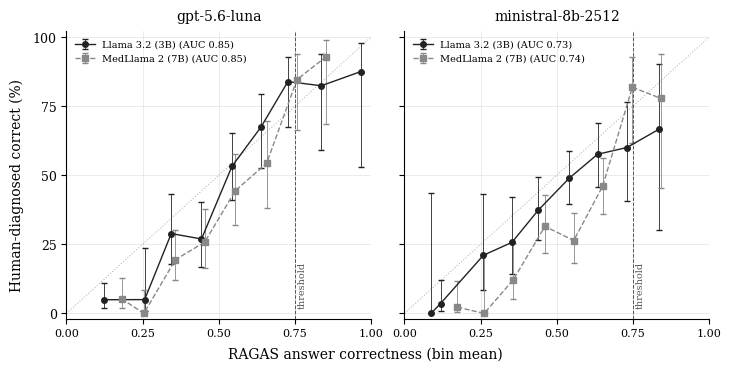

In [20]:
calibration_styles = {
    "Llama": {"color": "#222222", "marker": "o", "linestyle": "-", "offset": -0.008},
    "MedLlama": {"color": "#888888", "marker": "s", "linestyle": "--", "offset": 0.008},
}
with plt.rc_context(RAGAS_PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.6), sharex=True, sharey=True, layout="constrained")
    for ax, version in zip(axes, VERSIONS):
        ax.plot([0, 1], [0, 1], color="#bbbbbb", linestyle=":", linewidth=0.8)
        ax.axvline(CORRECTNESS_THRESHOLD, color="#555555", linestyle="--", linewidth=0.7)
        for model in MODELS:
            style = calibration_styles[model]
            points = calibration.loc[
                calibration["version"].eq(version) & calibration["model"].eq(model) & calibration["n"].ge(MIN_BIN_SIZE)
            ]
            x = points["mean_answer_correctness"] + style["offset"]
            y = points["human_correct_rate"]
            auc = separation.loc[(version, model), "answer_correctness_auc"]
            ax.errorbar(
                x, y, yerr=[y - points["ci_low"], points["ci_high"] - y],
                color=style["color"], marker=style["marker"], linestyle=style["linestyle"],
                markersize=4, linewidth=1, elinewidth=0.6, capsize=2,
                label=f"{RAGAS_MODEL_LABELS[model]} (AUC {auc:.2f})",
            )
        ax.text(CORRECTNESS_THRESHOLD + 0.01, 0.02, "threshold", fontsize=7, color="#555555", rotation=90, va="bottom")
        ax.set_title(JUDGE_MODELS[version], fontsize=10, pad=8)
        ax.set_xlim(0, 1)
        ax.set_ylim(-0.02, 1.02)
        ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0", "25", "50", "75", "100"])
        ax.grid(color="#e3e3e3", linewidth=0.5)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="upper left", frameon=False, fontsize=7)
    fig.supxlabel("RAGAS answer correctness (bin mean)", fontsize=10)
    fig.supylabel("Human-diagnosed correct (%)", fontsize=10)
    for extension in ["png", "svg", "pdf"]:
        fig.savefig(HUMAN_DIR / f"01_answer_correctness_vs_human.{extension}", dpi=600, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### Context recall vs human context verdict

**Figure caption:** RAGAS context recall for human-diagnosed failures, split by
whether the retrieved context contained the answer (`generation_miss`) or lacked
it (`retrieval_miss`). Boxes show the median and interquartile range; points are
individual rows with horizontal jitter. AUC above each model is the probability
that a generation miss scores higher context recall than a retrieval miss.
Human-correct answers are excluded because correctness does not establish
whether the context contained the answer.

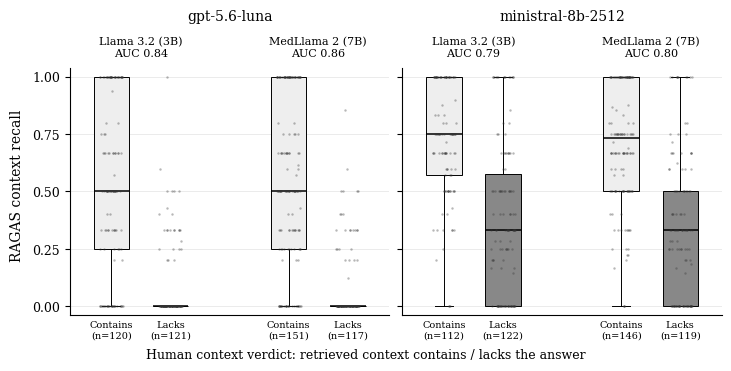

In [21]:
context_groups = [("generation_miss", "Contains"), ("retrieval_miss", "Lacks")]
context_colors = {"generation_miss": "#eeeeee", "retrieval_miss": "#888888"}
jitter = np.random.default_rng(2026)
with plt.rc_context(RAGAS_PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.6), sharey=True, layout="constrained")
    for ax, version in zip(axes, VERSIONS):
        tick_positions, tick_labels = [], []
        for model_index, model in enumerate(MODELS):
            rows = ragas_human.loc[ragas_human["version"].eq(version) & ragas_human["model"].eq(model)]
            positions = [model_index * 3 + 1, model_index * 3 + 2]
            values = [
                rows.loc[rows["diagnosis"].eq(diagnosis), "context_recall"].dropna().to_numpy()
                for diagnosis, _ in context_groups
            ]
            boxes = ax.boxplot(
                values, positions=positions, widths=0.6, patch_artist=True, showfliers=False,
                medianprops={"color": "black", "linewidth": 1.1}, boxprops={"linewidth": 0.7},
                whiskerprops={"linewidth": 0.7}, capprops={"linewidth": 0.7},
            )
            for box, (diagnosis, _) in zip(boxes["boxes"], context_groups):
                box.set_facecolor(context_colors[diagnosis])
            for position, scores in zip(positions, values):
                ax.scatter(position + jitter.uniform(-0.2, 0.2, len(scores)), scores, s=3,
                           color="#333333", alpha=0.35, linewidths=0, zorder=3)
            auc = separation.loc[(version, model), "context_recall_auc"]
            ax.text(np.mean(positions), 1.08, f"{RAGAS_MODEL_LABELS[model]}\nAUC {auc:.2f}",
                    ha="center", va="bottom", fontsize=8)
            tick_positions += positions
            tick_labels += [f"{label}\n(n={len(scores)})" for (_, label), scores in zip(context_groups, values)]
        ax.set_xticks(tick_positions, tick_labels, fontsize=7)
        ax.set_xlim(0.3, 5.7)
        ax.set_ylim(-0.04, 1.04)
        ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
        ax.set_title(JUDGE_MODELS[version], fontsize=10, pad=34)
        ax.tick_params(axis="x", length=0)
        ax.grid(axis="y", color="#e3e3e3", linewidth=0.5)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    fig.supxlabel("Human context verdict: retrieved context contains / lacks the answer", fontsize=9)
    fig.supylabel("RAGAS context recall", fontsize=10)
    for extension in ["png", "svg", "pdf"]:
        fig.savefig(HUMAN_DIR / f"02_context_recall_vs_human.{extension}", dpi=600, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [22]:
human_story = ["### What the RAGAS-human comparison shows", ""]
for version in VERSIONS:
    for model in MODELS:
        record = separation.loc[(version, model)]
        above = ragas_human.loc[
            ragas_human["version"].eq(version) & ragas_human["model"].eq(model) & ragas_human["human_answer_correct"],
            "answer_correctness",
        ].ge(CORRECTNESS_THRESHOLD).mean()
        human_story.append(
            f"- **{JUDGE_MODELS[version]} / {RAGAS_MODEL_LABELS[model]}:** answer correctness AUC "
            f"{record.answer_correctness_auc:.2f} (median {record.median_ac_correct:.2f} for human-correct vs "
            f"{record.median_ac_failure:.2f} for failures; {above:.1%} of human-correct answers reach "
            f"{CORRECTNESS_THRESHOLD}). Context recall AUC {record.context_recall_auc:.2f} (median "
            f"{record.median_cr_generation_miss:.2f} when the context contains the answer vs "
            f"{record.median_cr_retrieval_miss:.2f} when it lacks it)."
        )
human_story += [
    "",
    "**Interpretation:** AUC measures ranking agreement with the human diagnosis, independent of any threshold. "
    "The share of human-correct answers reaching the threshold shows how much of the judge's flagging comes "
    "from the threshold rather than the ranking. Context results cover human-diagnosed failures only.",
]
human_story_text = "\n".join(human_story)
display(Markdown(human_story_text))
_ = (HUMAN_DIR / "ragas_vs_human_interpretation.md").write_text(human_story_text + "\n", encoding="utf-8")

### What the RAGAS-human comparison shows

- **gpt-5.6-luna / Llama 3.2 (3B):** answer correctness AUC 0.85 (median 0.61 for human-correct vs 0.31 for failures; 21.8% of human-correct answers reach 0.75). Context recall AUC 0.84 (median 0.50 when the context contains the answer vs 0.00 when it lacks it).
- **gpt-5.6-luna / MedLlama 2 (7B):** answer correctness AUC 0.85 (median 0.59 for human-correct vs 0.33 for failures; 22.6% of human-correct answers reach 0.75). Context recall AUC 0.86 (median 0.50 when the context contains the answer vs 0.00 when it lacks it).
- **ministral-8b-2512 / Llama 3.2 (3B):** answer correctness AUC 0.73 (median 0.57 for human-correct vs 0.43 for failures; 8.7% of human-correct answers reach 0.75). Context recall AUC 0.79 (median 0.75 when the context contains the answer vs 0.33 when it lacks it).
- **ministral-8b-2512 / MedLlama 2 (7B):** answer correctness AUC 0.74 (median 0.61 for human-correct vs 0.48 for failures; 11.9% of human-correct answers reach 0.75). Context recall AUC 0.80 (median 0.73 when the context contains the answer vs 0.33 when it lacks it).

**Interpretation:** AUC measures ranking agreement with the human diagnosis, independent of any threshold. The share of human-correct answers reaching the threshold shows how much of the judge's flagging comes from the threshold rather than the ranking. Context results cover human-diagnosed failures only.